# Phase 4 — Model comparison and AP-selected manageable grids

Goal: subscription targeting **before campaign initiation**. All 15 predictors remain Provisional. We evaluate three primary course models: Logistic Regression, Decision Tree, Random Forest. No class weighting, resampling, new split, threshold optimization or held-out evaluation. Phase 3 baseline and approved preprocessing stay unchanged.

## Colab and inputs

Upload this notebook with `preprocessing.py`, `02_cleaned_dataset.csv`, `03_split_indices.json`, and `04_baseline_summary.md`, or set PROJECT_DIR to a mounted Drive project folder. Standard Colab supplies sklearn >=1.2, NumPy, pandas and Matplotlib. Raw `dataset.csv` is optional and is byte-hashed only when present. This notebook produces `05_model_comparison_summary.md`; figures/tables are embedded when the executed notebook is saved. No fitted models or new datasets are exported. Runtime can take several minutes on Colab; all searches run sequentially to bound CPU/memory.

Reviewed README, project DOCX, Phase 2C summary/data/split, preprocessing and the Phase 3 notebook/summary. The exact cleaned-file hash binds row content/order to saved positions; only development rows are parsed. Held-out indices are inspected for coverage/separation only, never used to load features/labels. No new train-test partition is generated.

## 1. Load only the saved development partition


In [1]:
from pathlib import Path
import sys,json,hashlib,warnings,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV,ParameterGrid
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,roc_curve,precision_recall_curve
from IPython.display import display
PROJECT_DIR=Path.cwd()  # mounted Drive project path also supported
required=['02_cleaned_dataset.csv','03_split_indices.json','preprocessing.py','04_baseline_summary.md']
if any(not (PROJECT_DIR/n).is_file() for n in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place required files in PROJECT_DIR') from exc
    files.upload()
if any(not (PROJECT_DIR/n).is_file() for n in required):raise FileNotFoundError(required)
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor,make_cv,FEATURES,CATEGORICAL,NUMERICAL,RECENCY

def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes={n:sha(PROJECT_DIR/n) for n in required}
if (PROJECT_DIR/'dataset.csv').is_file():input_hashes['dataset.csv']=sha(PROJECT_DIR/'dataset.csv')
split=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
assert input_hashes['02_cleaned_dataset.csv']==split['input_sha256']
assert split['row_count']==41176
idx=np.asarray(split['development_indices'],dtype=int)
held=np.asarray(split['held_out_indices'],dtype=int)
assert len(idx)==32940 and len(held)==8236 and len(np.unique(idx))==len(idx) and len(np.unique(held))==len(held)
assert not np.intersect1d(idx,held).size
np.testing.assert_array_equal(np.sort(np.r_[idx,held]),np.arange(41176))
keep=set(idx.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda n:n>0 and n-1 not in keep)
assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
dev.index=np.sort(idx);dev=dev.loc[idx].copy()
assert not dev.isna().any().any() and dev.y.isin([0,1]).all()
X=dev[FEATURES].copy();y=dev.y.copy();original_dev=dev.copy(deep=True)
folds=list(make_cv().split(X,y))
for (a,b),(aa,bb) in zip(folds,make_cv().split(X,y)):
    np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
seen=np.zeros(len(X),int)
for a,b in folds:
    assert len(a)==26352 and len(b)==6588 and not np.intersect1d(a,b).size
    assert not set(X.iloc[a].index).intersection(held) and not set(X.iloc[b].index).intersection(held)
    seen[b]+=1
assert (seen==1).all()
TRAIN_KEYS={frozenset(X.iloc[a].index):i+1 for i,(a,b) in enumerate(folds)}
VAL_KEYS={frozenset(X.iloc[b].index):i+1 for i,(a,b) in enumerate(folds)}
DEV_KEY=frozenset(X.index)
print('Saved hash/order verified. Development rows only:',X.shape,'positives:',int(y.sum()))
print('scikit-learn:',sklearn.__version__)



Saved hash/order verified. Development rows only: (32940, 15) positives: 3711
scikit-learn: 1.8.0


## 2. Prespecified configurations, budget and audits

Complete pipelines contain a fresh approved preprocessor plus estimator. LR matches Phase 3 (C=1, default L2, lbfgs, max_iter=1000); DT uses sklearn defaults; RF uses 100 trees and sklearn default depth/leaf/feature settings. Seeds are 42 and all class weights None. The same five StratifiedKFold(5,shuffle=True,random_state=42) development pairs are used everywhere.

AuditedPipeline is an experiment-only wrapper, not a replacement for preprocessing.py. It checks every training partition, learned vocabulary, ordinary mean/variance/scale/count and available-only recency statistics. Prediction is restricted to the exact saved development validation-fold indices; transformed numbers/probabilities must be finite and fitted parameters must be unchanged. Tree/RF numbers pass through; LR conditional recency uses the unchanged tested implementation. A fixed probability >=0.5 rule is used for every threshold metric, including exact ties, so comparisons do not depend on model-specific tie behavior.

Grids: LR C=[0.1,1,10] (3 candidates, fixed solver-compatible L2); DT depth=[5,10,None] × leaf=[10,50] (6); RF trees=[100,200] × depth=[10,None] × leaf=[5,20], max_features=sqrt (8). C regulates penalty strength; depth/leaf size regulate interactions and overfit; forest trees regulate stability/cost, feature sampling diversifies trees. DT split minimum and feature sampling remain defaults to avoid a large grid. No grid adaptively shrinks after results.

Optional HistGradientBoosting assessment before implementation: approved one-hot output is dense numeric and therefore compatible with its input interface; histogram-based nonlinear interactions suit tabular binary data. An extra model would add iterative histogram training and a learning_rate/max_iter/max_leaf_nodes/l2_regularization search. It could reuse the unscaled factory, keeping internal early stopping within the CV training fold. We defer this optional extension and execute only the three primary models; no boosting results are invented.

Budget: 15 untuned CV fits + 85 grid candidate-fold fits + 3 AP-selected development refits = 103 fits. No full-development preprocessing before CV. GridSearchCV's automatic refit occurs **after** selecting its winner; that fitted object's training predictions are not used for evaluation/targeting. AP is Average Precision, not trapezoidal PR area; probability-based ROC/AP and zero_division=0 precision/recall/F1 are consistent across stages.


In [2]:
METRICS=['Accuracy','Precision','Recall','F1','ROC_AUC','AP']

def scores(actual,prob):
    pred=(prob>=0.5).astype(int)
    return dict(Accuracy=accuracy_score(actual,pred),Precision=precision_score(actual,pred,zero_division=0),
        Recall=recall_score(actual,pred,zero_division=0),F1=f1_score(actual,pred,zero_division=0),
        ROC_AUC=roc_auc_score(actual,prob),AP=average_precision_score(actual,prob))

def signature(pre):
    ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical']
    num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
    out={'categories':[v.tolist() for v in enc.categories_],'names':pre.get_feature_names_out().tolist()}
    if hasattr(num,'mean_'):out['numeric']=[num.mean_.tolist(),num.var_.tolist(),num.scale_.tolist(),np.asarray(num.n_samples_seen_).tolist()]
    if hasattr(rec,'mean_'):out['recency']=[rec.mean_,rec.var_,rec.scale_,rec.n_available_]
    return out

FIT_AUDIT=[];PRED_AUDIT=[];WARNINGS=[];PHASE='untuned';CURRENT_MODEL='';ALLOW_REFIT=False

def audit_fit(est,data):
    key=frozenset(data.index)
    assert key in TRAIN_KEYS or (ALLOW_REFIT and key==DEV_KEY),'Unauthorized fit partition'
    pre=est.named_steps['preprocessing'];ct=pre.named_steps['preprocessor']
    enc=ct.named_transformers_['categorical'];num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
    for col,levels in zip(CATEGORICAL,enc.categories_):np.testing.assert_array_equal(levels,np.sort(data[col].unique()))
    assert enc.drop is None and enc.handle_unknown=='ignore'
    if hasattr(num,'mean_'):
        np.testing.assert_allclose(num.mean_,data[NUMERICAL].mean(),rtol=1e-12,atol=1e-12)
        np.testing.assert_allclose(num.var_,data[NUMERICAL].var(ddof=0),rtol=1e-12,atol=1e-12)
        scale=np.sqrt(data[NUMERICAL].var(ddof=0).to_numpy());scale[scale==0]=1
        np.testing.assert_allclose(num.scale_,scale,rtol=1e-12,atol=1e-12)
        assert np.all(np.asarray(num.n_samples_seen_)==len(data))
    if hasattr(rec,'mean_'):
        observed=data.loc[data.recency_available.eq(1),'recency_days'].to_numpy()
        mean=float(observed.mean()) if len(observed) else 0.;var=float(observed.var(ddof=0)) if len(observed) else 0.
        scale=np.sqrt(var) if var>0 else 1.
        assert rec.n_available_==len(observed)
        np.testing.assert_allclose([rec.mean_,rec.var_,rec.scale_],[mean,var,scale],rtol=1e-12)
    FIT_AUDIT.append({'phase':PHASE,'model':CURRENT_MODEL,'fold':TRAIN_KEYS.get(key,'post-search refit'),
        'rows':len(data),'observed_recency':int(data.recency_available.sum()),
        'recency_mean':getattr(rec,'mean_',np.nan),'recency_scale':getattr(rec,'scale_',np.nan),'status':'PASS'})

class AuditedPipeline(Pipeline):
    """Experiment-only audit wrapper; approved preprocessing.py is imported unchanged."""
    def fit(self,X,y=None,**params):
        assert not hasattr(self.named_steps['preprocessing'].named_steps['preprocessor'],'transformers_')
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            result=super().fit(X,y,**params)
        for w in caught:WARNINGS.append({'phase':PHASE,'model':CURRENT_MODEL,'category':w.category.__name__,'message':str(w.message)})
        audit_fit(self,X)
        return result
    def predict_proba(self,X,**params):
        key=frozenset(X.index)
        assert key in VAL_KEYS,'Prediction restricted to fixed development validation folds'
        pre=self.named_steps['preprocessing'];before=signature(pre)
        z=pre.transform(X)
        assert np.isfinite(z).all() and z.shape[1]==len(pre.get_feature_names_out())
        np.testing.assert_array_equal(z[:,-1],X.recency_available)
        if hasattr(pre.named_steps['preprocessor'].named_transformers_['recency'],'mean_'):
            rec=pre.named_steps['preprocessor'].named_transformers_['recency'];available=X.recency_available.eq(1).to_numpy()
            assert (z[~available,-2]==0).all()
            np.testing.assert_allclose(z[available,-2],(X.loc[available,'recency_days']-rec.mean_)/rec.scale_)
        else:np.testing.assert_array_equal(z[:,-9:],X[NUMERICAL+RECENCY].to_numpy())
        probability=super().predict_proba(X,**params)
        assert signature(pre)==before and np.isfinite(probability).all()
        assert ((probability>=0)&(probability<=1)).all()
        PRED_AUDIT.append({'phase':PHASE,'model':CURRENT_MODEL,'fold':VAL_KEYS[key],'rows':len(X),'status':'PASS'})
        return probability

MODELS=['LogisticRegression','DecisionTree','RandomForest']

def factory(name):
    if name=='LogisticRegression':
        p='logistic_regression';clf=LogisticRegression(max_iter=1000,random_state=42,C=1.,class_weight=None,solver='lbfgs')
    elif name=='DecisionTree':p='decision_tree';clf=DecisionTreeClassifier(random_state=42,class_weight=None)
    elif name=='RandomForest':p='random_forest';clf=RandomForestClassifier(n_estimators=100,random_state=42,class_weight=None,n_jobs=1)
    else:raise ValueError(name)
    return AuditedPipeline([('preprocessing',make_preprocessor(p)),('classifier',clf)])

def scoring(est,data,actual):
    prob=est.predict_proba(data)[:,list(est.classes_).index(1)]
    return scores(actual,prob)

GRIDS={
 'LogisticRegression':{'classifier__C':[0.1,1.,10.]},
 'DecisionTree':{'classifier__max_depth':[5,10,None],'classifier__min_samples_leaf':[10,50]},
 'RandomForest':{'classifier__n_estimators':[100,200],'classifier__max_depth':[10,None],
                 'classifier__min_samples_leaf':[5,20],'classifier__max_features':['sqrt']}}
print('Prespecified grid configurations:',{n:len(ParameterGrid(g)) for n,g in GRIDS.items()})



Prespecified grid configurations: {'LogisticRegression': 3, 'DecisionTree': 6, 'RandomForest': 8}


## 3. Untuned common-fold experiments first

Each fold gets a fresh complete estimator and the original unencoded/unscaled training/validation data. OOF probability slots are assigned exactly once. LR rerun is compared with all five published Phase 3 score rows at their displayed six-decimal precision. Tree/forest impurity importance is gathered from each training model without selecting/removing features. Original features' one-hot levels are grouped together for reporting.


In [3]:
untuned_rows=[];untuned_audit=[];importance_rows=[];cost=[];oof={name:np.full(len(X),np.nan) for name in MODELS}
start_all=time.perf_counter()
for name in MODELS:
    CURRENT_MODEL=name;started=time.perf_counter()
    for fold,(tr,va) in enumerate(folds,start=1):
        est=factory(name);t=time.perf_counter();est.fit(X.iloc[tr],y.iloc[tr]);fit_seconds=time.perf_counter()-t
        prob=est.predict_proba(X.iloc[va])[:,list(est.classes_).index(1)]
        oof[name][va]=prob
        untuned_rows.append({'model':name,'fold':fold,**scores(y.iloc[va],prob)})
        clf=est.named_steps['classifier']
        untuned_audit.append({'model':name,'fold':fold,'fit_seconds':fit_seconds,
            'iterations':int(np.max(clf.n_iter_)) if hasattr(clf,'n_iter_') else 'not applicable',
            'features':len(est.named_steps['preprocessing'].get_feature_names_out()),'status':'PASS'})
        if hasattr(clf,'feature_importances_'):
            enc=est.named_steps['preprocessing'].named_steps['preprocessor'].named_transformers_['categorical']
            origins=[col for col,levels in zip(CATEGORICAL,enc.categories_) for _ in levels]+NUMERICAL+RECENCY
            assert len(origins)==len(clf.feature_importances_)
            grouped=pd.Series(clf.feature_importances_).groupby(origins).sum()
            for col,value in grouped.items():importance_rows.append({'model':name,'fold':fold,'feature':col,'importance':value})
        print('Untuned completed:',name,'fold',fold)
    assert np.isfinite(oof[name]).all()
    cost.append({'model':name,'stage':'untuned CV','configurations':1,'CV_fits':5,'refits':0,'wall_seconds':time.perf_counter()-started})
untuned=pd.DataFrame(untuned_rows);assert np.isfinite(untuned[METRICS].to_numpy()).all()
# Preserve Phase 3 results and compare the rerun LR scores with its published rounded table.
reference=[]
for line in (PROJECT_DIR/'04_baseline_summary.md').read_text().splitlines():
    if line.startswith('| LogisticRegression |'):
        parts=[v.strip() for v in line.split('|')[1:-1]]
        if len(parts)==8 and parts[1] in ['1','2','3','4','5']:reference.append([float(v) for v in parts[2:]])
assert len(reference)==5
np.testing.assert_allclose(untuned.loc[untuned.model=='LogisticRegression',METRICS].to_numpy(),np.asarray(reference),rtol=0,atol=5.1e-7)
print('Phase 3 reference reproduced within its six-decimal published precision.')
display(untuned)



Untuned completed: LogisticRegression fold 1
Untuned completed: LogisticRegression fold 2
Untuned completed: LogisticRegression fold 3
Untuned completed: LogisticRegression fold 4
Untuned completed: LogisticRegression fold 5
Untuned completed: DecisionTree fold 1
Untuned completed: DecisionTree fold 2
Untuned completed: DecisionTree fold 3
Untuned completed: DecisionTree fold 4
Untuned completed: DecisionTree fold 5
Untuned completed: RandomForest fold 1
Untuned completed: RandomForest fold 2
Untuned completed: RandomForest fold 3
Untuned completed: RandomForest fold 4
Untuned completed: RandomForest fold 5
Phase 3 reference reproduced within its six-decimal published precision.


,model,fold,Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,LogisticRegression,1,0.899211,0.665254,0.211590,0.321063,0.774180,0.432213
1,LogisticRegression,2,0.899059,0.680751,0.195418,0.303665,0.759074,0.420763
2,LogisticRegression,3,0.897845,0.653333,0.198113,0.304033,0.742628,0.403407
3,LogisticRegression,4,0.898300,0.680000,0.183288,0.288747,0.770513,0.425606
4,LogisticRegression,5,0.901184,0.725490,0.199192,0.312566,0.764998,0.428919
5,DecisionTree,1,0.828476,0.287746,0.354447,0.317633,0.622349,0.179376
6,DecisionTree,2,0.838950,0.311688,0.355795,0.332284,0.631238,0.193183
7,DecisionTree,3,0.828931,0.289617,0.357143,0.319855,0.627261,0.183706
8,DecisionTree,4,0.836521,0.298436,0.334232,0.315321,0.616298,0.178609
9,DecisionTree,5,0.830753,0.273171,0.301480,0.286628,0.601934,0.168939


## 4. GridSearchCV with AP refit — model-selection estimates

The joint scorer returns all six metrics from positive-class probabilities using the fixed 0.5 rule. `GridSearchCV(scoring=scoring,refit='AP',cv=folds,n_jobs=1,error_score='raise')` clones complete pipelines independently. Every candidate-fold fit/prediction is audited. Fitting a winner on development after selection is permitted for the GridSearch refit only and is explicitly counted; no fitted artifact is exported.

The winning configuration's reported split scores come from the same folds used to select it and can be optimistic. They are not nested CV and not independent test performance. We do **not** generate tuned winner predictions from reused tuning folds and label them unbiased OOF.


In [4]:
PHASE='grid search';ALLOW_REFIT=True
searches={};candidate_tables=[];selected_rows=[];best_rows=[]
for name in MODELS:
    CURRENT_MODEL=name;started=time.perf_counter();n=len(ParameterGrid(GRIDS[name]))
    search=GridSearchCV(factory(name),GRIDS[name],scoring=scoring,refit='AP',cv=folds,
        n_jobs=1,error_score='raise',return_train_score=False,verbose=0)
    search.fit(X,y)
    elapsed=time.perf_counter()-started
    searches[name]=search;best=search.best_index_;r=search.cv_results_
    for candidate,params in enumerate(r['params']):
        row={'model':name,'parameters':json.dumps(params,sort_keys=True),'rank_AP':int(r['rank_test_AP'][candidate]),'mean_fit_seconds':r['mean_fit_time'][candidate]}
        for metric in METRICS:
            values=np.asarray([r[f'split{i}_test_{metric}'][candidate] for i in range(5)])
            assert np.isfinite(values).all()
            row[metric+'_mean']=float(values.mean());row[metric+'_SD']=float(values.std(ddof=1))
        candidate_tables.append(row)
    for fold in range(5):
        selected_rows.append({'model':name,'fold':fold+1,**{metric:float(r[f'split{fold}_test_{metric}'][best]) for metric in METRICS}})
    best_rows.append({'model':name,'best_parameters':json.dumps(search.best_params_,sort_keys=True),'selection_AP':search.best_score_})
    cost.append({'model':name,'stage':'GridSearchCV','configurations':n,'CV_fits':5*n,'refits':1,'wall_seconds':elapsed})
    print('Grid complete:',name, '| best AP',search.best_score_,'| seconds',round(elapsed,2))
ALLOW_REFIT=False
selected=pd.DataFrame(selected_rows);candidates=pd.DataFrame(candidate_tables);best_params=pd.DataFrame(best_rows)
assert np.isfinite(selected[METRICS].to_numpy()).all()
assert len(FIT_AUDIT)==103  # 15 untuned + 85 search-CV fits + 3 post-search refits
assert len(PRED_AUDIT)==100  # only fixed validation folds; never full-development or held-out predictions
assert sum(a['rows']==len(X) for a in FIT_AUDIT)==3
assert all(a['status']=='PASS' for a in FIT_AUDIT+PRED_AUDIT)
display(best_params);display(selected)



Grid complete: LogisticRegression | best AP 0.4224294027810701 | seconds 1.69
Grid complete: DecisionTree | best AP 0.4204990497822444 | seconds 4.16
Grid complete: RandomForest | best AP 0.44541699483257347 | seconds 96.44


,model,best_parameters,selection_AP
0,LogisticRegression,"{""classifier__C"": 0.1}",0.422429
1,DecisionTree,"{""classifier__max_depth"": null, ""classifier__m...",0.420499
2,RandomForest,"{""classifier__max_depth"": 10, ""classifier__max...",0.445417


,model,fold,Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,LogisticRegression,1,0.899211,0.671053,0.206199,0.315464,0.773340,0.432797
1,LogisticRegression,2,0.899970,0.698565,0.196765,0.307045,0.758226,0.420805
2,LogisticRegression,3,0.897996,0.660550,0.194070,0.300000,0.742708,0.403262
3,LogisticRegression,4,0.897996,0.678571,0.179245,0.283582,0.770552,0.425777
4,LogisticRegression,5,0.900729,0.725888,0.192463,0.304255,0.764549,0.429507
5,DecisionTree,1,0.897237,0.598784,0.265499,0.367880,0.776334,0.428947
6,DecisionTree,2,0.896934,0.618868,0.221024,0.325720,0.767976,0.411627
7,DecisionTree,3,0.898148,0.628159,0.234501,0.341511,0.766785,0.399164
8,DecisionTree,4,0.897086,0.595808,0.268194,0.369888,0.782669,0.442709
9,DecisionTree,5,0.896023,0.607407,0.220727,0.323791,0.765224,0.420048


## 5. Performance and business metrics

Mean and sample SD (ddof=1) are computed from five individual folds for both untuned models and the selected tuned configuration. GridSearchCV's default standard deviations use ddof=0, so they are recomputed explicitly. All candidate AP/ROC summaries are displayed and the full multi-metric cv_results_ remains in notebook memory. Do not interpret dependent-fold variation as a confidence interval.

Only **untuned** probabilities feed Precision@K, Recall@K and Lift@K for top 5%, 10%, 20%. K=ceil(fraction*N), ties break by saved cleaned row position without outcomes. Precision is historical subscribers/contact count; recall is captured/all subscribers; lift compares precision to development prevalence. These are historical predictive associations, not evidence calling causes subscription. No assumed costs, value or outreach capacity. Wider coverage may capture more subscribers with lower precision/lift, but actual measurements determine the pattern.

Pooled OOF ranks mix five fitted probability scales and overlapping training sets. We show fold-local ranking mean/SD as an additional diagnostic. Unbiased tuned targeting is deferred: five-outer/five-inner nested tuning of these grids would require 440 fits across all families versus 88 grid/refit fits here, plus these baseline fits. Nested estimates still would not fix missing timing/client metadata. Approval is needed before spending that budget.


In [5]:
combined=pd.concat([untuned.assign(stage='untuned'),selected.assign(stage='tuned selection CV')],ignore_index=True)
means=combined.groupby(['stage','model'])[METRICS].mean();sds=combined.groupby(['stage','model'])[METRICS].std(ddof=1)
comparison=pd.DataFrame(index=means.index)
for metric in METRICS:comparison[metric+' mean ± SD']=[f'{means.loc[i,metric]:.6f} ± {sds.loc[i,metric]:.6f}' for i in means.index]
display(comparison)
display(candidates[['model','parameters','rank_AP','AP_mean','AP_SD','ROC_AUC_mean','mean_fit_seconds']])
business=[];fold_business=[];prevalence=float(y.mean())

def topk(actual,prob,fraction,tie_positions):
    # Exactly ceil(fraction*N); deterministic tie-break uses saved row positions, never outcomes.
    k=int(np.ceil(len(actual)*fraction))
    order=np.lexsort((np.asarray(tie_positions),-np.asarray(prob)))
    labels=np.asarray(actual);captured=int(labels[order[:k]].sum());total=int(labels.sum())
    precision=captured/k;recall=captured/total;lift=precision/(total/len(labels))
    return dict(contacts=k,captured_subscribers=captured,Precision_at_K=precision,Recall_at_K=recall,Lift_at_K=lift)
for name,prob in oof.items():
    for fraction in [.05,.10,.20]:
        business.append({'model':name,'target_fraction':fraction,**topk(y,prob,fraction,X.index)})
        for fold,(_,va) in enumerate(folds,start=1):
            fold_business.append({'model':name,'target_fraction':fraction,'fold':fold,**topk(y.iloc[va],prob[va],fraction,X.iloc[va].index)})
business=pd.DataFrame(business);fold_business=pd.DataFrame(fold_business)
assert np.isfinite(business.select_dtypes('number').to_numpy()).all()
display(business)
# Pooled OOF ranks mix five independently fitted probability scales; fold-local ranks are shown too.
fold_target_summary=fold_business.groupby(['model','target_fraction'])[['Precision_at_K','Recall_at_K','Lift_at_K']].agg(['mean','std'])
display(fold_target_summary)
importance=pd.DataFrame(importance_rows).groupby(['model','feature']).importance.agg(['mean','std']).reset_index()
display(importance.sort_values(['model','mean'],ascending=[True,False]))



Accuracy mean ± SD  ...         AP mean ± SD
stage              model                                    ...                     
tuned selection CV DecisionTree        0.897086 ± 0.000759  ...  0.420499 ± 0.016574
                   LogisticRegression  0.899180 ± 0.001207  ...  0.422429 ± 0.011606
                   RandomForest        0.899514 ± 0.000872  ...  0.445417 ± 0.016226
untuned            DecisionTree        0.832726 ± 0.004730  ...  0.180763 ± 0.008793
                   LogisticRegression  0.899120 ± 0.001282  ...  0.422181 ± 0.011316
                   RandomForest        0.883394 ± 0.002188  ...  0.361307 ± 0.010715

[6 rows x 6 columns]

,model,parameters,rank_AP,AP_mean,AP_SD,ROC_AUC_mean,mean_fit_seconds
0,LogisticRegression,"{""classifier__C"": 0.1}",1,0.422429,0.011606,0.761875,0.089728
1,LogisticRegression,"{""classifier__C"": 1.0}",2,0.422181,0.011316,0.762279,0.074936
2,LogisticRegression,"{""classifier__C"": 10.0}",3,0.422112,0.011427,0.762429,0.074046
3,DecisionTree,"{""classifier__max_depth"": 5, ""classifier__min_...",4,0.398487,0.018946,0.779219,0.079445
4,DecisionTree,"{""classifier__max_depth"": 5, ""classifier__min_...",3,0.404168,0.016611,0.781041,0.079546
5,DecisionTree,"{""classifier__max_depth"": 10, ""classifier__min...",5,0.387560,0.014266,0.759113,0.108595
6,DecisionTree,"{""classifier__max_depth"": 10, ""classifier__min...",2,0.420319,0.017907,0.775270,0.107202
7,DecisionTree,"{""classifier__max_depth"": null, ""classifier__m...",6,0.352227,0.018575,0.730012,0.146301
8,DecisionTree,"{""classifier__max_depth"": null, ""classifier__m...",1,0.420499,0.016574,0.771797,0.125383
9,RandomForest,"{""classifier__max_depth"": 10, ""classifier__max...",2,0.445087,0.016845,0.791393,1.343890


,model,target_fraction,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,LogisticRegression,0.05,1647,960,0.582878,0.258690,5.173808
1,LogisticRegression,0.10,3294,1562,0.474196,0.420911,4.209108
2,LogisticRegression,0.20,6588,2269,0.344414,0.611425,3.057127
3,DecisionTree,0.05,1647,255,0.154827,0.068715,1.374293
4,DecisionTree,0.10,3294,875,0.265634,0.235786,2.357855
5,DecisionTree,0.20,6588,1332,0.202186,0.358933,1.794665
6,RandomForest,0.05,1647,826,0.501518,0.222582,4.451630
7,RandomForest,0.10,3294,1397,0.424104,0.376448,3.764484
8,RandomForest,0.20,6588,2126,0.322708,0.572891,2.864457


Precision_at_K            ... Lift_at_K          
                                             mean       std  ...      mean       std
model              target_fraction                           ...                    
DecisionTree       0.05                  0.151515  0.031199  ...  1.344896  0.277007
                   0.10                  0.265250  0.026748  ...  2.354424  0.237200
                   0.20                  0.202883  0.012358  ...  1.800896  0.110490
LogisticRegression 0.05                  0.578788  0.029768  ...  5.137432  0.262463
                   0.10                  0.475266  0.009501  ...  4.218594  0.083517
                   0.20                  0.344006  0.011626  ...  3.053493  0.102722
RandomForest       0.05                  0.504242  0.020619  ...  4.475862  0.184449
                   0.10                  0.423369  0.008380  ...  3.757973  0.075556
                   0.20                  0.322458  0.007158  ...  2.862240  0.063473

[9 rows x 6 columns]

,model,feature,mean,std
0,DecisionTree,age,0.197607,0.008157
11,DecisionTree,nr.employed,0.164057,0.003545
6,DecisionTree,euribor3m,0.152197,0.005599
8,DecisionTree,job,0.110597,0.005798
4,DecisionTree,education,0.089790,0.004669
7,DecisionTree,housing,0.054599,0.003006
10,DecisionTree,marital,0.049077,0.006632
9,DecisionTree,loan,0.038473,0.003010
1,DecisionTree,cons.conf.idx,0.031154,0.001690
13,DecisionTree,recency_available,0.031001,0.000762


## 6. Development-only plots and interpretation boundaries

ROC/PR and targeting plots use untuned OOF predictions only. Training-derived grouped mean-decrease-in-impurity plots are **not** permutation importance, causal influence or a feature-selection rule. Correlated economic variables can divide/displace importance and high-cardinality split opportunities can bias it. One-hot aggregation aids readability, not unbiased inference.

LR is easier to express through log odds but needs coefficient/reference conventions and caution with correlated features. Single-tree rules can be readable yet deep defaults can overfit or become unwieldy. Forests add interactions and averaging but sacrifice simple rules. Optional boosting adds sequential flexibility and compute without guaranteed superiority. The best model need not be the most complex.


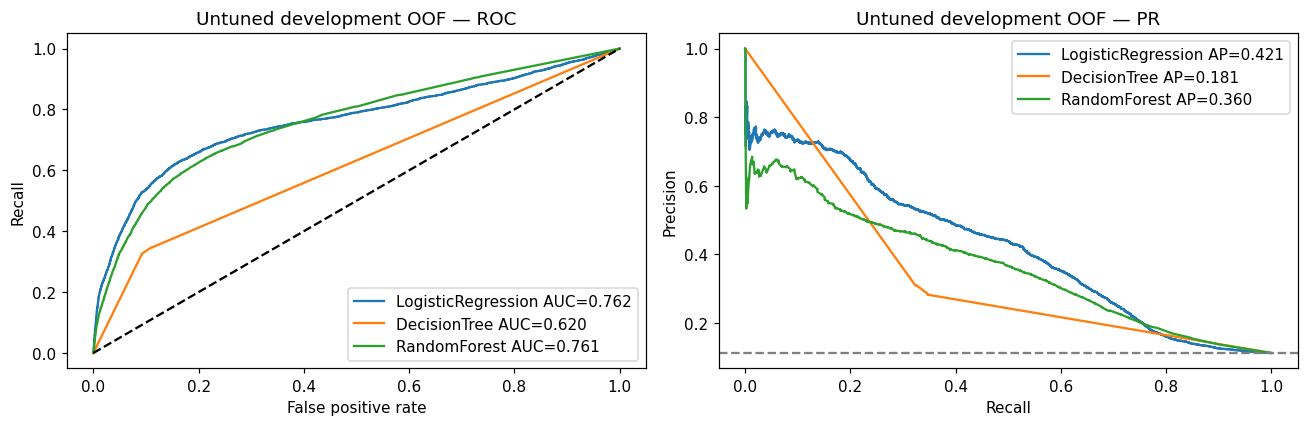

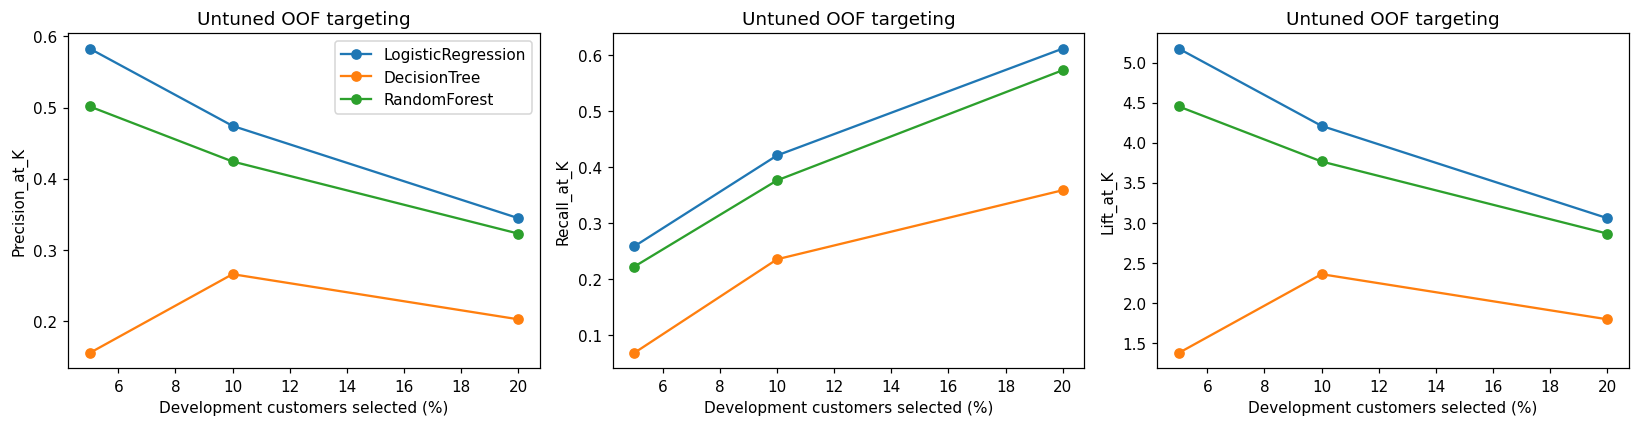

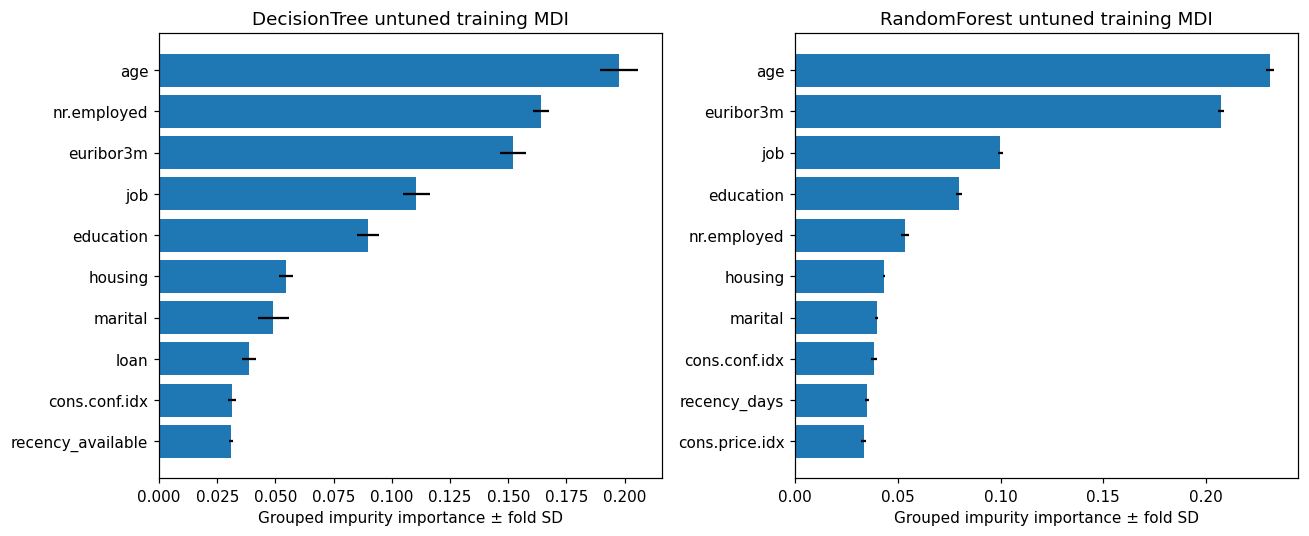

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,prob in oof.items():
    fpr,tpr,_=roc_curve(y,prob);precision,recall,_=precision_recall_curve(y,prob)
    axes[0].plot(fpr,tpr,label=f'{name} AUC={roc_auc_score(y,prob):.3f}')
    axes[1].plot(recall,precision,label=f'{name} AP={average_precision_score(y,prob):.3f}')
axes[0].plot([0,1],[0,1],'k--');axes[1].axhline(prevalence,color='gray',ls='--')
axes[0].set(xlabel='False positive rate',ylabel='Recall',title='Untuned development OOF — ROC')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Untuned development OOF — PR')
for ax in axes:ax.legend()
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['Precision_at_K','Recall_at_K','Lift_at_K']):
    for name in MODELS:
        b=business.loc[business.model==name];ax.plot(b.target_fraction*100,b[metric],marker='o',label=name)
    ax.set(xlabel='Development customers selected (%)',ylabel=metric,title='Untuned OOF targeting')
axes[0].legend();plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,name in zip(axes,['DecisionTree','RandomForest']):
    b=importance.loc[importance.model==name].nlargest(10,'mean').sort_values('mean')
    ax.barh(b.feature,b['mean'],xerr=b['std']);ax.set(title=name+' untuned training MDI',xlabel='Grouped impurity importance ± fold SD')
plt.tight_layout();plt.show()



## 7. Computational evidence, preservation and factual summary

Report all 103 fits and 100 fold-validation probability calls, measured runtime, best parameters and warning logs. Verify original/cleaned data, saved split, baseline summary and approved code hashes after experiments. No held-out matrix exists and no prediction on a post-search full-development refit is allowed by the audit wrapper.

All Provisional features remain: age, job, marital, education, default, housing, loan, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed, recency_available, recency_days. Timestamped customer snapshots, historical recency reference dates and economic release/revision vintages are unverified; label window is also unresolved. Missing client IDs/dates permit repeated-client and temporal overlap. Prior full-data EDA exposure must be disclosed. Preprocessing safeguards do not eliminate all leakage or certify performance on future campaigns/unseen clients.

Recommendations in the generated summary are based on observed AP/ROC/precision/recall/runtime and remain candidates for review, not final deployment choices. No threshold/class-weight/resampling or Phase 5 work begins automatically. Both deliverables remain uncommitted/unpushed pending approval.


In [7]:
cost=pd.DataFrame(cost);total_seconds=time.perf_counter()-start_all
fit_audit=pd.DataFrame(FIT_AUDIT);prediction_audit=pd.DataFrame(PRED_AUDIT)
audit_summary=fit_audit.groupby(['phase','model','rows']).size().rename('fit_count').reset_index()
display(cost);display(audit_summary)
display(pd.DataFrame(WARNINGS) if WARNINGS else pd.DataFrame({'warnings':['No estimator or convergence warnings recorded']}))
for name,digest in input_hashes.items():assert sha(PROJECT_DIR/name)==digest,name+' modified'
pd.testing.assert_frame_equal(dev,original_dev,check_exact=True)
assert all(est.best_estimator_.named_steps['classifier'].class_weight is None for est in searches.values())
print('All leakage/isolation/integrity assertions passed. Total seconds:',round(total_seconds,2))

def mdtable(frame,index=False):
    t=frame.reset_index() if index else frame.copy()
    def fmt(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,t.columns))+' |','| '+' | '.join(['---']*len(t.columns))+' |']+['| '+' | '.join(fmt(v) for v in r)+' |' for r in t.itertuples(index=False,name=None)])
ranked=means.loc['tuned selection CV'].sort_values('AP',ascending=False)
winner=ranked.index[0];untuned_rank=means.loc['untuned'].sort_values('AP',ascending=False)
reference_AP=means.loc[('untuned','LogisticRegression'),'AP']
changes=ranked[['AP','ROC_AUC']].copy();changes['AP_minus_Phase3_LR']=changes.AP-reference_AP
warntext=mdtable(pd.DataFrame(WARNINGS)) if WARNINGS else 'None recorded across all 103 fits.'
summary=f"""# Phase 4 — Model comparison and manageable hyperparameter tuning

## Scope, data and reproducibility

Compared Logistic Regression (LR), Decision Tree (DT) and Random Forest (RF), with random_state=42, class_weight=None, no resampling and a fixed probability >=0.5 decision threshold. Reused the existing development assignment (32,940 rows) from 03_split_indices.json; all 8,236 held-out rows remain unparsed/unused for training, tuning, metrics, plots or importance. No new train-test split. Cleaned input hash/order `{input_hashes['02_cleaned_dataset.csv']}` matched before row selection. Only development rows were materialized. Raw CSV was hash-checked if present, not parsed. All saved inputs, approved preprocessing and Phase 3 baseline files remain unchanged.

Reviewed README, project DOCX, cleaned dataset/split schema, preprocessing.py, Phase 2C summary and Phase 3 notebook/summary. No preprocessing reimplementation or transformer change. Versions: sklearn {sklearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}. Notebook requires sklearn >=1.2 and standard Colab packages; executed locally, not in hosted Colab.

## Models and optional extension assessment

Untuned LR exactly matches Phase 3: max_iter=1000, C=1, default L2, lbfgs, random_state=42, no class weighting. DT uses sklearn defaults plus random_state=42/class_weight=None. RF uses 100 trees, default depth=None/min_samples_leaf=1/max_features='sqrt', random_state=42, n_jobs=1, class_weight=None. The approved tree/RF preprocessing passes numbers without scaling; LR uses ordinary plus conditional scaling. All have full train-fitted one-hot encoding and separate recency days/availability.

Optional HistGradientBoostingClassifier was assessed but **not trained**. Approved one-hot output is dense finite numeric data (42 columns in the untuned folds), compatible with its numeric interface. Histogram boosting is appropriate for nonlinear tabular binary classification, but adds iterative histogram construction, model memory and another search (learning_rate, max_iter, max_leaf_nodes, l2_regularization). An actual implementation would reuse the unscaled factory, confirm supported sklearn/version behavior, and keep any early-stopping subset within the fold training data. Deferred to keep this experiment focused on the three primary course models and a bounded budget; no optional algorithm substituted.

## CV and grids declared before execution

Identical five fold index pairs from StratifiedKFold(5,shuffle=True,random_state=42) for every untuned model and every search candidate. Each training fold has 26,352 original unencoded/unscaled rows and validation has 6,588. Fresh complete estimator pipelines fit within every fold. Positive-class probabilities supply ROC-AUC/AP; precision/recall/F1 use zero_division=0. AP is Average Precision, not trapezoidal PR area. All reported fold SDs use ddof=1 (sample SD), recomputed from individual split scores (GridSearchCV's native std uses ddof=0). No significance or independent-test inference from these dependent folds.

- LR: C=[0.1,1,10] — 3 candidates, fixed compatible lbfgs/default L2. Smaller C strengthens regularization, larger C weakens it. Penalty is deliberately fixed to avoid a solver/regularizer expansion, not omitted accidentally.
- DT: max_depth=[5,10,None], min_samples_leaf=[10,50] — 6 candidates. Depth bounds interactions/complexity; leaf size regularizes small/noisy groups. min_samples_split stays 2 and max_features stays None to bound search; leaf size already constrains splits. No exhaustive search claim.
- RF: n_estimators=[100,200], max_depth=[10,None], min_samples_leaf=[5,20], max_features=['sqrt'] — 8 candidates. Trees count controls Monte Carlo stability/cost; depth and leaf size regulate complexity; feature subsampling diversifies trees, fixed at sqrt for computational control.

GridSearchCV uses a multi-metric probability scorer returning Accuracy/Precision/Recall/F1/ROC_AUC/AP, with refit='AP', n_jobs=1, error_score='raise', and the exact same fold list. Candidate counts: 17 total; 85 candidate-fold fits plus 3 winning full-development **post-search refits**. Untuned comparison adds 15 fold fits: **103 total fits**. Refit happens only after search, is not a pre-CV global transformation, and its training predictions are never evaluated or ranked. No grid was reduced after seeing results. Single-threaded estimator/search settings avoid nested CPU oversubscription.

## Untuned individual fold results

{mdtable(untuned)}

## Tuned selected-configuration fold results — model-selection estimates

{mdtable(selected)}

These are the five selection-fold scores for each family winner, chosen using those folds. They may be optimistic. They are not independent test performance and are not nested-CV estimates.

## Mean ± sample SD, both stages

{mdtable(comparison,index=True)}

Best hyperparameters:

{mdtable(best_params)}

All candidates (AP and ROC-AUC overview; complete multi-metric candidate results are retained by cv_results_ in notebook memory):

{mdtable(candidates[['model','parameters','rank_AP','AP_mean','AP_SD','ROC_AUC_mean','ROC_AUC_SD','mean_fit_seconds']])}

## Comparison with preserved Phase 3 LR

Untuned LR rerun matches all five published Phase 3 fold scores to their six-decimal rounding precision (AP mean {reference_AP:.6f}). Untuned AP ranking: {', '.join(untuned_rank.index)}. Tuned selection AP ranking: {', '.join(ranked.index)}. Highest selected AP is **{winner}: {ranked.iloc[0].AP:.6f}**, ROC-AUC {ranked.iloc[0].ROC_AUC:.6f}. The table below compares selected-CV mean scores with the untuned Phase 3 reference; selecting winners on these same folds can bias apparent improvements.

{mdtable(changes.rename_axis('model'),index=True)}

## Untuned development OOF business targeting

Every OOF probability comes from an untuned pipeline that excluded that customer's row during training. K=ceil(fraction*N); select exactly K with descending probability and saved cleaned-row position as deterministic, outcome-independent tie-break. Precision@K=captured/K, Recall@K=captured/total actual subscribers, Lift@K=Precision@K/development prevalence. Prevalence={prevalence:.6f} ({prevalence*100:.4f}%), actual development subscribers={int(y.sum()):,}. Historical predicted conversion is not a causal response-to-calling effect. Ties can materially affect targeting, especially for unpruned trees with coarse probabilities; the fixed row-position rule is reproducible but does not identify an optimal tie-break.

{mdtable(business)}

These pooled OOF ranks combine five fitted probability scales and their training sets overlap; they are a useful development diagnostic, not deployment evidence. For transparency, fold-local rank summaries (each validation cohort ranked separately) are also reported:

{mdtable(fold_target_summary.reset_index().set_axis(['model','fraction','Precision_mean','Precision_SD','Recall_mean','Recall_SD','Lift_mean','Lift_SD'],axis=1))}

The contacted counts represent historical development records, not an approved future campaign budget. Smaller groups can concentrate subscribers, while larger groups may capture more at lower precision/lift; inspect each actual table rather than assume monotonic precision. We do not know call costs, subscription value, treatment effects or capacity, so no financial optimum or capacity recommendation is inferred. The three targeting fractions are prespecified ranking diagnostics, not tuned probability thresholds.

**Tuned-model unbiased targeting is deferred.** No selected hyperparameters were rerun through the same tuning folds and called unbiased OOF. No in-sample winning-refit predictions are used for metrics/ranking. A nested design using five outer folds and the same five-fold inner grids would require 5*(85 inner fits+3 refits)=440 fits across three families (in addition to this comparison), versus 88 search/refit fits here. It would estimate the selection procedure more honestly, but still inherit feature-timing/client overlap limitations. Phase 5 approval is needed for a nested experiment; no equivalence of untuned OOF and tuned selection estimates is fabricated.

## Interpretability

LR offers directional log-odds coefficients but full one-hot coding, scaling and correlated indicators complicate interpretation; coefficients are not causal and need a stated reference/regularization convention. A DT can expose decision rules but the default unpruned tree can be large/unstable. RF averages trees and can represent nonlinear interactions, trading simple rules for ensemble complexity. Optional boosting adds sequential nonlinear flexibility and tuning/compute cost without guaranteed gains.

The notebook shows untuned training-derived mean-decrease-in-impurity importance, grouped from all one-hot columns back to each original feature, then averaged across five fold-trained DT/RF models. This is descriptive training-model interpretation, not validation permutation importance or evidence for feature removal. It can favor richer split opportunities, and correlated economic variables share or displace importance. Grouping avoids displaying each dummy as an unrelated concept but does not remove bias. No feature selection was performed.

{mdtable(importance.sort_values(['model','mean'],ascending=[True,False]))}

## Computational cost and audits

{mdtable(cost)}

Measured elapsed time through experiments/plots: {total_seconds:.2f} seconds on this runtime; not a forecast for Colab. Grid mean fit times above exclude scoring/refit overhead. RF cost increases with number/depth of trees, so a small score difference must be weighed against runtime/complexity, not automatically favor the complex model. No fit failures triggered grid reduction.

{mdtable(audit_summary)}

An experiment-only Pipeline subclass audits every fit, including GridSearchCV clones, without modifying preprocessing.py. Every fit's indices match an approved fold-training partition, except the three explicitly labelled post-search full-development refits. Each encoder vocabulary equals fit-row levels; LR scaler mean/variance/scale/count match training rows; conditional recency mean/variance/scale/count use only availability=1 fitting rows. All 100 validation predictions are on fixed development validation folds; parameters remain unchanged through transform. Numeric matrices/probabilities are finite, unavailable transformed recency remains zero, the availability bit remains unscaled, and tree/RF numbers are passed through unchanged. Object factories create fresh preprocessors; no global encoded/scaled matrix is shared across folds. All audit assertions passed.

Warnings/errors recorded:

{warntext}

All previous input hashes, saved split, raw/cleaned data, Phase 3 notebook/summary and approved preprocessing remain unchanged. No held-out prediction/evaluation, class weights, SMOTE/undersampling, threshold optimization or automatic next-phase work.

## Phase 5 candidates and unresolved approval

Advance **{winner}** as the leading AP-selected candidate for review, while preserving **Logistic Regression** as the transparent/simple reference. This is a provisional development-selection recommendation, not a final model or independent-performance claim. Review the full AP/ROC/precision/recall/cost tables before deciding whether any other family merits further work; model complexity alone is not evidence of superiority. Approve a selection-bias-aware validation plan before interpreting tuned targeting or selecting a deployment configuration.

All 15 predictors remain Provisional: {', '.join(FEATURES)}. Confirm campaign-start customer/status snapshots, historical previous/recency cutoff and pdays reference dates, economic publication/revision timing, and target outcome window. Missing client IDs/campaign timestamps permit repeated-client/temporal overlap across random stratified folds; prior whole-dataset EDA exposure also needs disclosure. Preprocessing isolation does not eliminate feature-timing leakage or guarantee future-campaign/unseen-customer performance.

Team decisions still needed: candidate shortlist; whether to budget nested CV and/or optional boosting; valid timing metadata/assumptions; treatment of correlated indicators and rare levels in future experiments; business capacity/error costs and whether later threshold/class-weight experiments are authorized. None of these additional experiments was started. Existing saved holdout must remain reserved for a later approved evaluation.

Deliverables: executed 05_model_comparison.ipynb and this summary in the repository. No commit or push; Phase 4 stops pending review.
"""
(PROJECT_DIR/'05_model_comparison_summary.md').write_text(summary)
print('Summary saved; no commit, push or Phase 5 execution.')


All leakage/isolation/integrity assertions passed. Total seconds: 116.08
Summary saved; no commit, push or Phase 5 execution.


,model,stage,configurations,CV_fits,refits,wall_seconds
0,LogisticRegression,untuned CV,1,5,0,0.575625
1,DecisionTree,untuned CV,1,5,0,0.968842
2,RandomForest,untuned CV,1,5,0,11.395223
3,LogisticRegression,GridSearchCV,3,15,1,1.691800
4,DecisionTree,GridSearchCV,6,30,1,4.157416
5,RandomForest,GridSearchCV,8,40,1,96.440842


,phase,model,rows,fit_count
0,grid search,DecisionTree,26352,30
1,grid search,DecisionTree,32940,1
2,grid search,LogisticRegression,26352,15
3,grid search,LogisticRegression,32940,1
4,grid search,RandomForest,26352,40
5,grid search,RandomForest,32940,1
6,untuned,DecisionTree,26352,5
7,untuned,LogisticRegression,26352,5
8,untuned,RandomForest,26352,5


,warnings
0,No estimator or convergence warnings recorded
